In [1]:

import os
import torch
import transformers
import peft
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image, ImageOps
from pathlib import Path
from tqdm.auto import tqdm
from IPython.display import display

from transformers import (
    AutoProcessor,
    Qwen2_5_VLForConditionalGeneration
)

from peft import PeftModel
from huggingface_hub import snapshot_download

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("PEFT:", peft.__version__)
print("CUDA available:", torch.cuda.is_available())

assert torch.cuda.is_available(), "Enable GPU in Kaggle Settings!"

print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory:",
      round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
      "GB")


PyTorch: 2.11.0+cu128
Transformers: 5.16.1
PEFT: 0.20.0
CUDA available: True
GPU: Tesla T4
GPU memory: 14.56 GB


In [2]:

# Base Qwen model already mounted in Kaggle

BASE_MODEL_PATH = (
    "/kaggle/input/models/qwen-lm/"
    "qwen2.5-vl/transformers/3b-instruct/2"
)

# Hugging Face repositories
ADAPTER_REPO = "IDK-Chaitanya/SAGE5Class-cp"
DATASET_REPO = "IDK-Chaitanya/SAGE5class"

# Exact Tomato checkpoint
CHECKPOINT_FOLDER = "tomato/checkpoints/checkpoint-step-600"

# Download directories
ADAPTER_DOWNLOAD_DIR = "/kaggle/working/sage_adapter_repo"
DATASET_PATH = "/kaggle/working/SAGE5class"

# Evaluation output
OUTPUT_PATH = "/kaggle/working/tomato_evaluation_final"

os.makedirs(OUTPUT_PATH, exist_ok=True)

print("Base model exists:", os.path.isdir(BASE_MODEL_PATH))
print("Adapter repository:", ADAPTER_REPO)
print("Tomato checkpoint:", CHECKPOINT_FOLDER)
print("Dataset repository:", DATASET_REPO)

assert os.path.isdir(BASE_MODEL_PATH), "Base model path not found!"


Base model exists: True
Adapter repository: IDK-Chaitanya/SAGE5Class-cp
Tomato checkpoint: tomato/checkpoints/checkpoint-step-600
Dataset repository: IDK-Chaitanya/SAGE5class


In [3]:

print("Base model files:")

for filename in os.listdir(BASE_MODEL_PATH):
    print(filename)

required_base_files = [
    "config.json",
    "preprocessor_config.json"
]

for filename in required_base_files:
    filepath = os.path.join(BASE_MODEL_PATH, filename)
    print(filename, ":", os.path.exists(filepath))

assert os.path.exists(
    os.path.join(BASE_MODEL_PATH, "config.json")
), "Base model config.json missing!"


Base model files:
model.safetensors.index.json
config.json
merges.txt
model-00001-of-00002.safetensors
LICENSE
model-00002-of-00002.safetensors
preprocessor_config.json
README.md
tokenizer.json
vocab.json
tokenizer_config.json
chat_template.json
generation_config.json
config.json : True
preprocessor_config.json : True


In [4]:

snapshot_download(
    repo_id=ADAPTER_REPO,
    repo_type="model",
    allow_patterns=[
        f"{CHECKPOINT_FOLDER}/*"
    ],
    local_dir=ADAPTER_DOWNLOAD_DIR
)

ADAPTER_PATH = os.path.join(
    ADAPTER_DOWNLOAD_DIR,
    CHECKPOINT_FOLDER
)

print("Downloaded checkpoint:", ADAPTER_PATH)

assert os.path.isdir(ADAPTER_PATH), "Checkpoint folder missing!"

print("\nCheckpoint contents:")

for filename in sorted(os.listdir(ADAPTER_PATH)):
    print(filename)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Downloaded checkpoint: /kaggle/working/sage_adapter_repo/tomato/checkpoints/checkpoint-step-600

Checkpoint contents:
README.md
adapter_config.json
adapter_model.safetensors
chat_template.jinja
optimizer.pt
processor_config.json
scheduler.pt
tokenizer.json
tokenizer_config.json
trainer_state.json


In [5]:

import json

config_path = os.path.join(
    ADAPTER_PATH,
    "adapter_config.json"
)

weights_path = os.path.join(
    ADAPTER_PATH,
    "adapter_model.safetensors"
)

assert os.path.isfile(config_path), "adapter_config.json missing!"
assert os.path.isfile(weights_path), "adapter_model.safetensors missing!"

with open(config_path, "r") as file:
    adapter_config = json.load(file)

print("Adapter configuration:")
print(json.dumps(adapter_config, indent=2))

print("\nAdapter rank:", adapter_config.get("r"))
print("Adapter alpha:", adapter_config.get("lora_alpha"))
print("Target modules:", adapter_config.get("target_modules"))
print("Base model reference:", adapter_config.get("base_model_name_or_path"))

print("\nCheckpoint file size:",
      round(os.path.getsize(weights_path) / (1024**2), 2), "MB")

print("\nCheckpoint verification successful!")


Adapter configuration:
{
  "alora_invocation_tokens": null,
  "alpha_pattern": {},
  "arrow_config": null,
  "auto_mapping": null,
  "base_model_name_or_path": "/kaggle/input/models/qwen-lm/qwen2.5-vl/transformers/3b-instruct/2",
  "bias": "none",
  "corda_config": null,
  "ensure_weight_tying": false,
  "eva_config": null,
  "exclude_modules": null,
  "fan_in_fan_out": false,
  "inference_mode": true,
  "init_lora_weights": true,
  "layer_replication": null,
  "layers_pattern": null,
  "layers_to_transform": null,
  "loftq_config": {},
  "lora_alpha": 32,
  "lora_bias": false,
  "lora_dropout": 0.05,
  "lora_ga_config": null,
  "megatron_config": null,
  "megatron_core": "megatron.core",
  "modules_to_save": null,
  "monteclora_config": null,
  "peft_type": "LORA",
  "peft_version": "0.20.0",
  "qalora_group_size": 16,
  "r": 16,
  "rank_pattern": {},
  "revision": null,
  "target_modules": [
    "gate_proj",
    "o_proj",
    "down_proj",
    "up_proj",
    "v_proj",
    "k_proj",
  

In [8]:

from transformers import AutoProcessor

PROCESSOR_REPO = "Qwen/Qwen2.5-VL-3B-Instruct"

processor = AutoProcessor.from_pretrained(
    PROCESSOR_REPO,
    trust_remote_code=True
)

print("Processor loaded successfully!")
print("Processor:", type(processor))
print("Tokenizer:", type(processor.tokenizer))
print("Image processor:", type(processor.image_processor))


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Processor loaded successfully!
Processor: <class 'transformers.models.qwen2_5_vl.processing_qwen2_5_vl.Qwen2_5_VLProcessor'>
Tokenizer: <class 'transformers.models.qwen2.tokenization_qwen2.Qwen2Tokenizer'>
Image processor: <class 'transformers.models.qwen2_vl.image_processing_qwen2_vl.Qwen2VLImageProcessor'>


In [9]:

base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    BASE_MODEL_PATH,
    torch_dtype=torch.float16,
    device_map="auto",
    trust_remote_code=True,
    attn_implementation="sdpa",
    local_files_only=True
)

base_model.eval()

print("Qwen base model loaded successfully!")
print("Model class:", type(base_model).__name__)
print("Model device:", base_model.device)

print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")


Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

Qwen base model loaded successfully!
Model class: Qwen2_5_VLForConditionalGeneration
Model device: cuda:0
GPU memory allocated: 6.81 GB


In [11]:
!pip uninstall -y torchao
!pip install -U torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 41.7 MB/s  0:00:00


In [12]:

model = PeftModel.from_pretrained(
    base_model,
    ADAPTER_PATH,
    adapter_name="tomato",
    is_trainable=False
)

model.set_adapter("tomato")
model.eval()

print("Tomato LoRA loaded!")

print("Registered adapters:", model.peft_config.keys())
print("Active adapter:", model.active_adapter)

assert "tomato" in model.peft_config, "Tomato adapter not registered!"
assert model.active_adapter == "tomato", "Tomato adapter is not active!"

assert len(model.peft_config) == 1, (
    "Unexpected additional adapters found. Check the notebook session."
)

print("\nCorrect Tomato adapter is active.")


Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_cutlass_90a.abi3.so
Failed to load /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so: Could not load this library: /usr/local/lib/python3.13/dist-packages/torchao/_C_mxfp8.cpython-310-x86_64-linux-gnu.so


Tomato LoRA loaded!
Registered adapters: dict_keys(['tomato'])
Active adapter: tomato

Correct Tomato adapter is active.


In [13]:

from safetensors.torch import load_file
import torch
import os

# 1. Read the actual Hugging Face checkpoint
weight_path = os.path.join(
    ADAPTER_PATH,
    "adapter_model.safetensors"
)

checkpoint_state = load_file(weight_path)

print("=" * 60)
print("CHECKPOINT FILE")
print("=" * 60)

print("Checkpoint tensors:", len(checkpoint_state))
print(
    "Checkpoint parameters:",
    sum(t.numel() for t in checkpoint_state.values())
)

print("\nFirst 10 checkpoint tensor names:")

for name, tensor in list(checkpoint_state.items())[:10]:
    print(name, tuple(tensor.shape))

# 2. Inspect all loaded model parameters
print("\n" + "=" * 60)
print("LOADED MODEL PARAMETERS")
print("=" * 60)

all_lora_params = {
    name: param
    for name, param in model.named_parameters()
    if "lora_" in name.lower()
}

print("Loaded LoRA tensors:", len(all_lora_params))

print(
    "Loaded LoRA parameters:",
    sum(p.numel() for p in all_lora_params.values())
)

print("\nFirst 15 loaded LoRA parameter names:")

for name, param in list(all_lora_params.items())[:15]:
    print(
        name,
        tuple(param.shape),
        "requires_grad =", param.requires_grad
    )

# 3. Check whether loaded LoRA weights are non-zero
nonzero_params = sum(
    torch.count_nonzero(param.detach()).item()
    for param in all_lora_params.values()
)

total_params = sum(
    param.numel()
    for param in all_lora_params.values()
)

print("\n" + "=" * 60)
print("VERIFICATION SUMMARY")
print("=" * 60)

print("Active adapter:", model.active_adapter)
print("Checkpoint tensors:", len(checkpoint_state))
print("Loaded LoRA tensors:", len(all_lora_params))
print("Loaded LoRA parameters:", total_params)
print("Non-zero parameters:", nonzero_params)

if len(checkpoint_state) > 0 and len(all_lora_params) > 0:
    print("\nLoRA tensors detected. Continue with further verification.")
else:
    print("\nWARNING: Checkpoint or loaded LoRA tensors are missing.")


CHECKPOINT FILE
Checkpoint tensors: 696
Checkpoint parameters: 37152768

First 10 checkpoint tensor names:
base_model.model.model.language_model.layers.0.mlp.down_proj.lora_A.weight (16, 11008)
base_model.model.model.language_model.layers.0.mlp.down_proj.lora_B.weight (2048, 16)
base_model.model.model.language_model.layers.0.mlp.gate_proj.lora_A.weight (16, 2048)
base_model.model.model.language_model.layers.0.mlp.gate_proj.lora_B.weight (11008, 16)
base_model.model.model.language_model.layers.0.mlp.up_proj.lora_A.weight (16, 2048)
base_model.model.model.language_model.layers.0.mlp.up_proj.lora_B.weight (11008, 16)
base_model.model.model.language_model.layers.0.self_attn.k_proj.lora_A.weight (16, 2048)
base_model.model.model.language_model.layers.0.self_attn.k_proj.lora_B.weight (256, 16)
base_model.model.model.language_model.layers.0.self_attn.o_proj.lora_A.weight (16, 2048)
base_model.model.model.language_model.layers.0.self_attn.o_proj.lora_B.weight (2048, 16)

LOADED MODEL PARAMETER

In [14]:

snapshot_download(
    repo_id=DATASET_REPO,
    repo_type="dataset",
    allow_patterns=[
        "split_images/val/Tomato/**"
    ],
    local_dir=DATASET_PATH
)

TOMATO_PATH = os.path.join(
    DATASET_PATH,
    "split_images",
    "val",
    "Tomato"
)

assert os.path.isdir(TOMATO_PATH), "Tomato validation folder missing!"

print("Validation folder:", TOMATO_PATH)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 200 files:   0%|          | 0/200 [00:00<?, ?it/s]

Validation folder: /kaggle/working/SAGE5class/split_images/val/Tomato


In [15]:

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp", ".bmp"
}

image_records = []

for class_folder in sorted(Path(TOMATO_PATH).iterdir()):

    if not class_folder.is_dir():
        continue

    actual_disease = class_folder.name.replace("_", " ")

    for image_path in sorted(class_folder.rglob("*")):

        if image_path.suffix.lower() in IMAGE_EXTENSIONS:

            image_records.append({
                "image_path": str(image_path),
                "actual_label": actual_disease
            })

CLASS_NAMES = sorted({
    record["actual_label"]
    for record in image_records
})

print("Total images:", len(image_records))
print("Total classes:", len(CLASS_NAMES))

for disease in CLASS_NAMES:

    count = sum(
        record["actual_label"] == disease
        for record in image_records
    )

    print(f"{disease}: {count}")

assert len(image_records) == 200, (
    f"Expected 200 images, found {len(image_records)}"
)

assert len(CLASS_NAMES) == 8, (
    f"Expected 8 classes, found {len(CLASS_NAMES)}"
)

assert all(
    sum(r["actual_label"] == disease for r in image_records) == 25
    for disease in CLASS_NAMES
), "Validation set is not balanced as expected!"

print("\nValidation dataset verified.")


Total images: 200
Total classes: 8
Bacterial Leaf Spot: 25
Early Blight: 25
Late Blight: 25
Leaf Mold: 25
Leaf Mosaic Virus: 25
Septoria Leaf Blotch: 25
Target Spot: 25
Tomato Leaf Curl Virus: 25

Validation dataset verified.


In [16]:

EVAL_PROMPT = """
Identify the disease in this tomato leaf image.

Choose exactly one class from the following list:
Bacterial Leaf Spot,
Early Blight,
Late Blight,
Leaf Mold,
Leaf Mosaic Virus,
Septoria Leaf Blotch,
Target Spot,
Tomato Leaf Curl Virus.

Return only the exact disease class name.
Do not repeat the instruction.
Do not explain the answer.
Do not return JSON.
"""

MAX_NEW_TOKENS = 32
DO_SAMPLE = False

print("Evaluation prompt:")
print(EVAL_PROMPT)


Evaluation prompt:

Identify the disease in this tomato leaf image.

Choose exactly one class from the following list:
Bacterial Leaf Spot,
Early Blight,
Late Blight,
Leaf Mold,
Leaf Mosaic Virus,
Septoria Leaf Blotch,
Target Spot,
Tomato Leaf Curl Virus.

Return only the exact disease class name.
Do not repeat the instruction.
Do not explain the answer.
Do not return JSON.



In [17]:

def get_input_device(model):

    return model.get_input_embeddings().weight.device


def predict_image(image_path):

    with Image.open(image_path) as opened:

        image = ImageOps.exif_transpose(
            opened
        ).convert("RGB")

    messages = [{
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": EVAL_PROMPT
            }
        ]
    }]

    inputs = processor.apply_chat_template(
        messages,
        tokenize=True,
        add_generation_prompt=True,
        return_dict=True,
        return_tensors="pt"
    )

    inputs = inputs.to(get_input_device(model))

    input_token_count = inputs["input_ids"].shape[1]

    with torch.inference_mode():

        generated = model.generate(
            **inputs,
            max_new_tokens=MAX_NEW_TOKENS,
            do_sample=DO_SAMPLE,
            use_cache=True
        )

    new_tokens = generated[:, input_token_count:]

    response = processor.batch_decode(
        new_tokens,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0].strip()

    return {
        "raw_response": response,
        "input_token_count": int(input_token_count),
        "generated_token_count": int(new_tokens.shape[1])
    }


print("Prediction function defined.")


Prediction function defined.


In [18]:

import re
import json

def normalize_text(text):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(text).lower()
    )


def extract_prediction(raw_response):

    if not raw_response:
        return "Unknown"

    text = raw_response.strip()

    # Accept JSON only when the predicted value matches a class
    try:

        obj = json.loads(text)

        if isinstance(obj, dict):

            candidate = (
                obj.get("disease")
                or obj.get("class_name")
                or obj.get("predicted_disease")
                or obj.get("prediction")
            )

            if isinstance(candidate, str):

                for disease in CLASS_NAMES:

                    if normalize_text(candidate) == normalize_text(disease):
                        return disease

    except (json.JSONDecodeError, TypeError):
        pass

    # Accept explicitly labelled predictions
    match = re.search(
        r"(?im)^\s*(?:predicted\s+disease|disease|answer|class)\s*:\s*(.+?)\s*$",
        text
    )

    if match:

        candidate = match.group(1).strip().strip("\"'` .")

        for disease in CLASS_NAMES:

            if normalize_text(candidate) == normalize_text(disease):
                return disease

    # Accept an exact class name and nothing else
    candidate = text.strip().strip("\"'` .")

    for disease in CLASS_NAMES:

        if normalize_text(candidate) == normalize_text(disease):
            return disease

    return "Unknown"


print("Strict parser defined.")


Strict parser defined.


Actual disease: Bacterial Leaf Spot


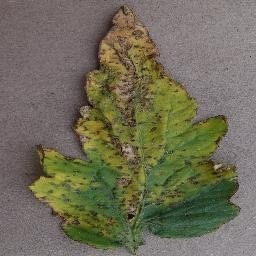


Raw model response:
'Septoria Leaf Blotch'

Parsed prediction:
Septoria Leaf Blotch

Active adapter: tomato


In [19]:

model.set_adapter("tomato")
model.eval()

test_record = image_records[0]

print("Actual disease:", test_record["actual_label"])

display(
    Image.open(test_record["image_path"]).convert("RGB")
)

test_result = predict_image(test_record["image_path"])

print("\nRaw model response:")
print(repr(test_result["raw_response"]))

print("\nParsed prediction:")
print(extract_prediction(test_result["raw_response"]))

print("\nActive adapter:", model.active_adapter)


In [ ]:

model.set_adapter("tomato")
model.eval()

assert model.active_adapter == "tomato"

results = []

print("Starting Tomato evaluation...")
print("Active adapter:", model.active_adapter)
print("Total images:", len(image_records))

for index, record in enumerate(
    tqdm(image_records, desc="Tomato evaluation")
):

    try:

        inference = predict_image(record["image_path"])

        raw_response = inference["raw_response"]

        predicted = extract_prediction(raw_response)

        results.append({
            "image": record["image_path"],
            "actual": record["actual_label"],
            "predicted": predicted,
            "correct": predicted == record["actual_label"],
            "raw_response": raw_response,
            "input_tokens": inference["input_token_count"],
            "generated_tokens": inference["generated_token_count"],
            "status": "Success"
        })

    except Exception as error:

        results.append({
            "image": record["image_path"],
            "actual": record["actual_label"],
            "predicted": "Unknown",
            "correct": False,
            "raw_response": str(error),
            "input_tokens": None,
            "generated_tokens": None,
            "status": "Error"
        })

    if (index + 1) % 10 == 0:

        last = results[-1]

        print(
            f"\n[{index + 1}/200] "
            f"Actual: {last['actual']} | "
            f"Predicted: {last['predicted']} | "
            f"Output: {last['raw_response'][:100]}"
        )

results_df = pd.DataFrame(results)

print("\nEvaluation completed.")

print("Successful:", (results_df["status"] == "Success").sum())
print("Errors:", (results_df["status"] == "Error").sum())
print("Unknown:", (results_df["predicted"] == "Unknown").sum())

display(results_df.head(10))


In [ ]:

CM_LABELS = CLASS_NAMES + ["Unknown"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=CM_LABELS
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CM_LABELS,
    yticklabels=CM_LABELS
)

plt.title("SAGE Tomato Disease - Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

confusion_path = os.path.join(
    OUTPUT_PATH,
    "tomato_confusion_matrix.png"
)

plt.savefig(
    confusion_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved:", confusion_path)


In [ ]:

# First: evaluate with Tomato adapter
model.set_adapter("tomato")

tomato_predictions = results_df["predicted"].tolist()

# Second: evaluate with LoRA disabled
base_predictions = []

with model.disable_adapter():

    for record in tqdm(
        image_records,
        desc="Base Qwen evaluation"
    ):

        try:

            result = predict_image(record["image_path"])

            prediction = extract_prediction(
                result["raw_response"]
            )

        except Exception as error:

            prediction = "Unknown"

        base_predictions.append(prediction)


base_accuracy = accuracy_score(
    [r["actual_label"] for r in image_records],
    base_predictions
)

tomato_accuracy = accuracy_score(
    [r["actual_label"] for r in image_records],
    tomato_predictions
)

print("\nBASE VS TOMATO LORA")
print("-" * 45)

print(f"Base Qwen accuracy : {base_accuracy * 100:.2f}%")
print(f"Tomato LoRA accuracy: {tomato_accuracy * 100:.2f}%")

print(
    "Accuracy difference:",
    f"{(tomato_accuracy - base_accuracy) * 100:+.2f} percentage points"
)


In [ ]:

y_true = results_df["actual"].tolist()
y_pred = results_df["predicted"].tolist()

accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    average="macro",
    zero_division=0
)

unknown_count = int(
    (results_df["predicted"] == "Unknown").sum()
)

error_count = int(
    (results_df["status"] == "Error").sum()
)

print("=" * 60)
print("SAGE - TOMATO DISEASE CLASSIFICATION")
print("=" * 60)

print(f"Total images       : {len(results_df)}")
print(f"Accuracy           : {accuracy * 100:.2f}%")
print(f"Macro Precision    : {macro_precision * 100:.2f}%")
print(f"Macro Recall       : {macro_recall * 100:.2f}%")
print(f"Macro F1           : {macro_f1 * 100:.2f}%")
print(f"Unknown predictions: {unknown_count}")
print(f"Inference errors   : {error_count}")

print("\nCLASSIFICATION REPORT")

print(classification_report(
    y_true,
    y_pred,
    labels=CLASS_NAMES,
    target_names=CLASS_NAMES,
    zero_division=0
))


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os

# Use only the current evaluation dataframe
y_true = results_df["actual"].tolist()
y_pred = results_df["predicted"].tolist()

# Keep exactly the eight disease classes
labels = CLASS_NAMES

# Metrics
accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true, y_pred,
    labels=labels,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred,
    labels=labels,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred,
    labels=labels,
    average="macro",
    zero_division=0
)

print("FINAL TOMATO EVALUATION")
print("=" * 55)
print("Images:", len(results_df))
print(f"Accuracy: {accuracy * 100:.2f}%")
print(f"Macro Precision: {macro_precision * 100:.2f}%")
print(f"Macro Recall: {macro_recall * 100:.2f}%")
print(f"Macro F1: {macro_f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=labels,
    target_names=labels,
    zero_division=0
))

# Confusion matrix from the exact same predictions
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

print("Correct predictions from matrix:", cm.trace())
print("Total predictions from matrix:", cm.sum())
print("Matrix accuracy:", cm.trace() / cm.sum())

assert cm.sum() == len(results_df)
assert abs(cm.trace() / cm.sum() - accuracy) < 1e-10

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("SAGE Tomato Disease - Final Confusion Matrix")
plt.xlabel("Predicted Disease")
plt.ylabel("Actual Disease")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

matrix_path = os.path.join(
    OUTPUT_PATH,
    "tomato_confusion_matrix_verified.png"
)

plt.savefig(matrix_path, dpi=300, bbox_inches="tight")
plt.show()

print("Verified matrix saved:", matrix_path)


In [ ]:

from IPython.display import display
from PIL import Image
import pandas as pd

problem_classes = [
    "Bacterial Leaf Spot",
    "Leaf Mosaic Virus",
    "Tomato Leaf Curl Virus",
    "Early Blight"
]

for disease in problem_classes:

    subset = results_df[
        results_df["actual"] == disease
    ]

    correct = subset[subset["correct"] == True].head(5)
    incorrect = subset[subset["correct"] == False].head(5)

    print("\n" + "=" * 65)
    print("DISEASE:", disease)
    print("Correct:", len(subset[subset["correct"] == True]))
    print("Incorrect:", len(subset[subset["correct"] == False]))
    print("=" * 65)

    for category, samples in [
        ("CORRECT PREDICTIONS", correct),
        ("INCORRECT PREDICTIONS", incorrect)
    ]:

        print("\n", category)

        for _, row in samples.iterrows():

            print(
                "Actual:", row["actual"],
                "| Predicted:", row["predicted"]
            )

            display(
                Image.open(row["image"]).convert("RGB").resize((300, 300))
            )
